# Libraries importation

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy.stats import norm
from scipy.stats import chi2


# Data collection

## Assets selection and assets weights

In [2]:
print("================= Welcome to the Portfolio Risk Engine! =====================")
print()

nb_tickers = int(input("How many tickers does your portfolio contain? "))

tickers = []
tickers_category = []
weights = []

# Minimum 6 tickers
if nb_tickers < 6:
    print("Portfolio not Valid! You need at least 6 tickers")

else:
    for i in range(nb_tickers):

        # Validation of ticker
        while True:

            ticker = input(f"Enter the {i+1} asset ticker: ").upper().strip()

            # Vérifier les doublons
            if ticker in tickers:
                print("Ticker already entered! Please enter another ticker.")
                continue

            try:
                asset = yf.Ticker(ticker)
                info = asset.info

                category = info.get("quoteType")

                if not category:
                    print("Ticker not found! Please enter a valid ticker.")
                    continue

                # Ajouter uniquement les tickers valides
                tickers.append(ticker)
                tickers_category.append(category)

                print(f"Ticker validated: {ticker}")
                print(f"Asset category: {category}")

                break

            except Exception as e:
                print(f"Error retrieving ticker: {e}")
                print("Please try again.")

        # Validation du poids
        while True:

            try:
                weight = float(input(f"Enter the weight of {ticker} (between 0 and 1): "))

                if 0 < weight <= 1:
                    weights.append(weight)
                    print(f"Weight registered: {weight}")
                    break

                else:
                    print("Weight must be greater than 0 and less than or equal to 1.")

            except ValueError:
                print("Invalid weight! Please enter a number.")

    # Validation finale du portefeuille

    if len(set(tickers_category)) < 3:
        print("Portfolio not Valid! You need at least 3 different asset categories.")

    elif (sum(weights)!=1):
        print("Portfolio not Valid! Sum of weights must equal 1.")
        print(f"Current total weight: {sum(weights)}")

    else:
        print()
        print("================= PORTFOLIO VALIDATED =================")
        print(f"Tickers: {tickers}")
        print(f"Asset categories: {tickers_category}")
        print(f"Weights: {weights}")
        print(f"Total weight: {sum(weights)}")
        print(f"Number of asset categories: {len(set(tickers_category))}")

================= Welcome to the Portfolio Risk Engine! =====================

Ticker validated: AMZN
Asset category: EQUITY
Weight registered: 0.2
Ticker validated: GC=F
Asset category: FUTURE
Weight registered: 0.05
Ticker validated: GLD
Asset category: ETF
Weight registered: 0.1
Ticker validated: BTC-USD
Asset category: CRYPTOCURRENCY
Weight registered: 0.1
Ticker validated: NVDA
Asset category: EQUITY
Weight registered: 0.3
Ticker validated: ^GSPC
Asset category: INDEX
Weight registered: 0.25

================= PORTFOLIO VALIDATED =================
Tickers: ['AMZN', 'GC=F', 'GLD', 'BTC-USD', 'NVDA', '^GSPC']
Asset categories: ['EQUITY', 'FUTURE', 'ETF', 'CRYPTOCURRENCY', 'EQUITY', 'INDEX']
Weights: [0.2, 0.05, 0.1, 0.1, 0.3, 0.25]
Total weight: 1.0
Number of asset categories: 5


In [3]:
data = yf.download (tickers, start='2017-01-01', end='2023-01-01')['Close']
data = pd.DataFrame(data).dropna()
data

[*********************100%***********************]  6 of 6 completed


Ticker,AMZN,BTC-USD,GC=F,GLD,NVDA,^GSPC
Date,,,,,,
2017-01-03,37.683498,1043.839966,1160.400024,110.470001,2.506343,2257.830078
2017-01-04,37.859001,1154.729980,1163.800049,110.860001,2.564818,2270.750000
2017-01-05,39.022499,1013.380005,1179.699951,112.580002,2.499708,2269.000000
2017-01-06,39.799500,902.200989,1171.900024,111.750000,2.533123,2276.979980
2017-01-09,39.846001,902.828003,1183.500000,112.669998,2.635823,2268.899902
...,...,...,...,...,...,...
2022-12-23,85.250000,16796.953125,1804.199951,167.259995,15.155331,3844.820068
2022-12-27,83.040001,16717.173828,1823.099976,168.669998,14.073945,3829.250000
2022-12-28,81.820000,16552.572266,1815.800049,167.910004,13.989228,3783.219971


# Analytics & models

## Portfolio return calculation

In [4]:
daily_returns = data.pct_change().dropna() #rendements journaliers
assets_returns = daily_returns.mean (axis=0) #moyennes des rendements par actifs
print (assets_returns)


Ticker
AMZN       0.000758
BTC-USD    0.003005
GC=F       0.000344
GLD        0.000322
NVDA       0.001668
^GSPC      0.000433
dtype: float64


In [5]:
portfolio = pd.DataFrame (index=tickers , columns= ['Returns', 'Weights'], dtype = float)
portfolio ['Returns'] = assets_returns
portfolio ['Weights'] = weights
print (portfolio)

          Returns  Weights
AMZN     0.000758     0.20
GC=F     0.000344     0.05
GLD      0.000322     0.10
BTC-USD  0.003005     0.10
NVDA     0.001668     0.30
^GSPC    0.000433     0.25


In [6]:
portfolio_return = portfolio['Returns']*portfolio['Weights']
print(f"Expected Portfolio Return: {portfolio_return.sum() * 100:.4f} %")

Expected Portfolio Return: 0.1110 %


## Correlation heatmap

<Axes: xlabel='Ticker', ylabel='Ticker'>

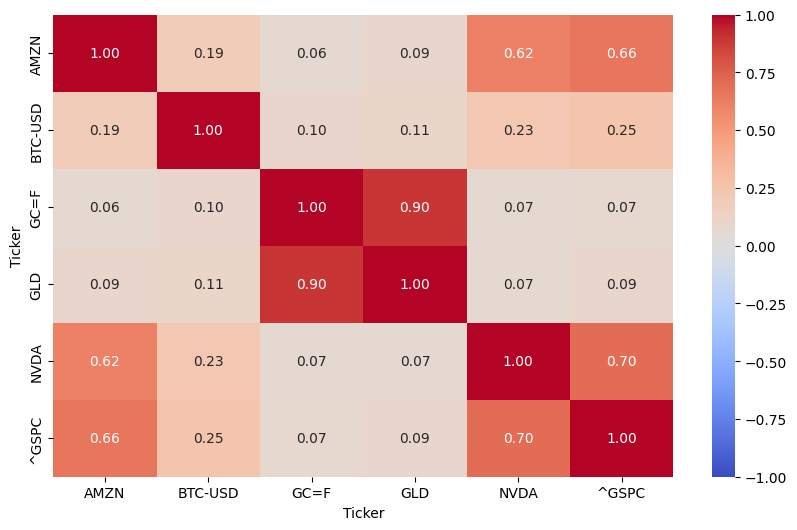

In [7]:
plt.figure(figsize=(10, 6))
sns.heatmap(daily_returns.corr(), vmin=-1, vmax=1, annot=True, cmap='coolwarm', fmt=".2f")

## Historical VaR

In [8]:
weights = pd.Series (portfolio ['Weights'] , index = daily_returns.columns)
print (weights)
pnl = daily_returns @ weights
#print (pnl)
sorted_pnl = pnl.sort_values(ascending=True)
print (sorted_pnl)


Ticker
AMZN       0.20
BTC-USD    0.10
GC=F       0.05
GLD        0.10
NVDA       0.30
^GSPC      0.25
Name: Weights, dtype: float64
Date
2020-03-12   -0.119078
2020-03-16   -0.108055
2022-06-13   -0.070540
2020-03-09   -0.065659
2022-09-13   -0.064580
                ...   
2020-03-17    0.067799
2020-04-06    0.069343
2020-03-13    0.076729
2020-03-24    0.091634
2022-11-10    0.096156
Length: 1508, dtype: float64


In [9]:
k_95 = len(sorted_pnl) * (0.05) # 5% quantile
k_99 = len(sorted_pnl) * (0.01) # 1% quantile
hist_var_95 = sorted_pnl.iloc [int(k_95)] # hist_var_95 = np.percentile(sorted_pnl, 5)
hist_var_99 = sorted_pnl.iloc [int(k_99)] # hist_var_99 = np.percentile(sorted_pnl, 1)


hist_cvar_95 = sorted_pnl [sorted_pnl <= hist_var_95].mean()  # Calculate CVaR as the mean of losses beyond VaR
hist_cvar_99 = sorted_pnl [sorted_pnl <= hist_var_99].mean()  # Calculate CVaR as the mean of losses beyond VaR

print (f'According to the historical method, the portfolio is expected to lose at least {- hist_var_95 * 100:.4f}% or more of its value in 5% of the worst cases and on average {-hist_cvar_95 * 100:.4f}% of its value in those cases.\n')
print (f'According to the historical method, the portfolio is expected to lose at least {- hist_var_99 * 100:.4f}% or more of its value in 1% of the worst cases and on average {-hist_cvar_99 * 100:.4f}% of its value in those cases.')

According to the historical method, the portfolio is expected to lose at least 2.6563% or more of its value in 5% of the worst cases and on average 4.0741% of its value in those cases.

According to the historical method, the portfolio is expected to lose at least 4.8599% or more of its value in 1% of the worst cases and on average 6.5561% of its value in those cases.


## Parametric VaR

In [10]:
portfolio_std_dev = np.sqrt(np.dot(weights.T, np.dot(daily_returns.cov(), weights))) #écart type/volatilité du portefeuille

p_95 = 0.95
p_99 = 0.99

param_var_95 = portfolio_return.sum() - (norm.ppf(p_95) * portfolio_std_dev)
param_var_99 = portfolio_return.sum() - (norm.ppf(p_99) * portfolio_std_dev)

print (f'According to the parametric method, the portfolio is expected to lose at least {-param_var_95 * 100:.4f}% or more of its value in 5% of the worst cases.\n')
print (f'According to the parametric method, the portfolio is expected to lose at least {-param_var_99 * 100:.4f}% or more of its value in 1% of the worst cases.\n')

According to the parametric method, the portfolio is expected to lose at least 2.7074% or more of its value in 5% of the worst cases.

According to the parametric method, the portfolio is expected to lose at least 3.8751% or more of its value in 1% of the worst cases.



# Simulation Monte Carlo

## Simulations des trajectoires

In [11]:
def simulation_gbm (weights, returns, cov, S0 = 1.0, n_days = 252, n_sim = 10000) : 
    np.random.seed (42)
    dt = 1
    
    returns = np.asarray (returns)
    port_values = np.zeros ((n_sim, n_days+1))
    port_values [:,0] = S0

    
    z = np.random.multivariate_normal (np.zeros(len(returns)), cov * dt, size=(n_sim, n_days))  #Composant aléatoire pour la simulation
            
    for t in range  (1, n_days + 1) : 
        asset_returns = (returns - 0.5 * np.diag(cov)) * dt + z [:, t-1]
        port_return = asset_returns @ weights
        port_values [:,t] = port_values [:, t-1] * np.exp (port_return)

    return port_values

In [12]:
simulated_portfolio_values = simulation_gbm (weights, assets_returns, daily_returns.cov(), n_days = 15) #n_days = 15 pour calculer la VaR sur 15 jours
print (simulated_portfolio_values)

[[1.         0.99223294 0.98278712 ... 0.97433203 0.94900631 0.95417853]
 [1.         1.0116532  1.01384153 ... 0.96040737 0.95552034 0.96100105]
 [1.         0.98178022 0.97743908 ... 0.93122795 0.93830126 0.93111711]
 ...
 [1.         1.00464857 0.98871358 ... 0.95568815 0.93093956 0.9078557 ]
 [1.         0.98475308 1.03512554 ... 1.00112589 0.98431883 0.97875416]
 [1.         0.98135733 0.9575344  ... 0.99170532 1.00640562 1.01767229]]


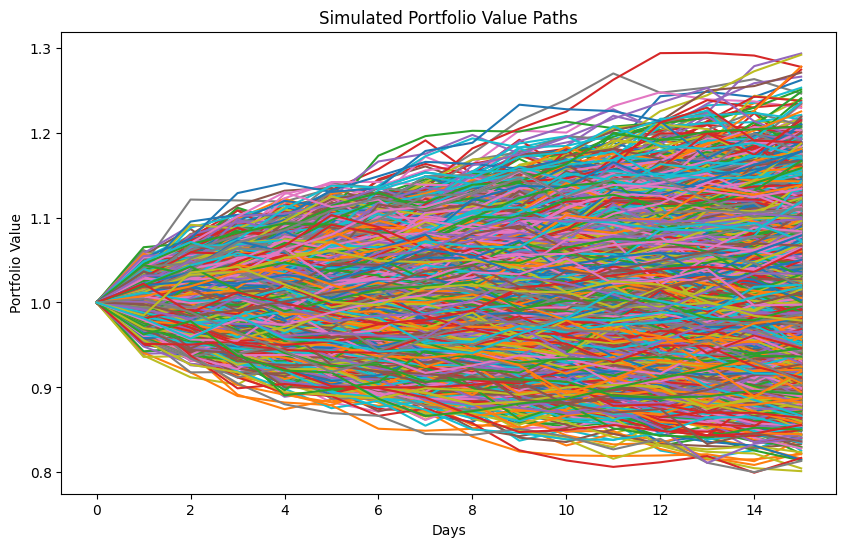

In [13]:
plt.figure(figsize=(10, 6))
t = np.linspace (0, 15, 16)

for i in range(simulated_portfolio_values.shape[0]):
    plt.plot(t, simulated_portfolio_values[i])
plt.title('Simulated Portfolio Value Paths')
plt.xlabel('Days')
plt.ylabel('Portfolio Value')
plt.show()

## Calcul VaR et CVaR

In [14]:
loss = simulated_portfolio_values[:,-1] - simulated_portfolio_values[:,0]
mc_var_95 = np.percentile(loss, 5)
mc_var_99 = np.percentile(loss, 1)
mc_cvar_95 = np.mean(loss[loss <= mc_var_95])
mc_cvar_99 = np.mean(loss[loss <= mc_var_99])

print (f'According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least {-mc_var_95 * 100:.4f}% or more of its value in 5% of the worst cases and on average {- mc_cvar_95 * 100:.4f}% of its value in those cases.\n')
print (f'According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least {-mc_var_99 * 100:.4f}% or more of its value in 1% of the worst cases and on average {- mc_cvar_99 * 100:.4f}% of its value in those cases.')

According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least 9.3487% or more of its value in 5% of the worst cases and on average 11.9187% of its value in those cases.

According to the Monte Carlo simulation, on a 15-day period the portfolio is expected to lose at least 13.5776% or more of its value in 1% of the worst cases and on average 15.4052% of its value in those cases.


# Stress test : correlation stress

In [15]:
#Covariance matrix reconstruction test

std = daily_returns.std () 
corr = daily_returns.corr ()
cov = np.diag (std) @ corr @ np.diag (std)
print (np.allclose (cov, daily_returns.cov()))


corr_stress = (1 - 0.75) * corr + 0.75 * np.ones_like (daily_returns.corr())
cov_stress = np.diag (std) @ corr_stress @ np.diag (std)
print (np.allclose (np.diag (cov_stress), std**2)) #the new cov mat has the same variance as the initial returns
display (cov_stress)

True
True


,0,1,2,3,4,5
0,0.000454,0.000818,0.000151,0.000142,0.000608,0.000247
1,0.000818,0.002316,0.000345,0.000323,0.001229,0.000496
2,0.000151,0.000345,0.000086,0.000078,0.000224,0.000090
3,0.000142,0.000323,0.000078,0.000075,0.000209,0.000085
4,0.000608,0.001229,0.000224,0.000209,0.000998,0.000371
5,0.000247,0.000496,0.000090,0.000085,0.000371,0.000161


In [16]:
coef = np.asarray ([0, 0.25, 0.5, 0.75, 1])
stress_test_table = pd.DataFrame (index=coef,columns=('VaR param', 'VaR MC', 'CVaR MC'), dtype= float)

for i in coef :
    #Covariance matrix recomposition
    corr_stress = (1 - i) * corr + i * np.ones_like (corr)
    cov_stress = np.dot (np.diag (std), np.dot (corr_stress, np.diag (std)))

    #Parametric VaR calculation
    std_stress = np.sqrt(weights.T @ cov_stress @ weights)
    p_95 = 0.95
    param_var = portfolio_return.sum() - (norm.ppf(p_95) * std_stress)
    stress_test_table.loc [i,'VaR param'] = param_var

    #Monte-Carlo VaR calculation
    stress_value = simulation_gbm (weights, assets_returns, cov_stress, n_days = 1) #n_days = 1 pour calculer la VaR à 1 jour
    stress_loss = stress_value[:,-1] - stress_value[:,0]
    st_mc_var = np.percentile(stress_loss, 5)
    st_mc_cvar = np.mean(stress_loss[stress_loss <= st_mc_var])
    stress_test_table.loc [i,'VaR MC'] = st_mc_var
    stress_test_table.loc [i, 'CVaR MC'] = st_mc_cvar


print (stress_test_table.round (4))


      VaR param  VaR MC  CVaR MC
0.00    -0.0271 -0.0271  -0.0337
0.25    -0.0298 -0.0294  -0.0370
0.50    -0.0323 -0.0321  -0.0401
0.75    -0.0346 -0.0345  -0.0430
1.00    -0.0368 -0.0368  -0.0456


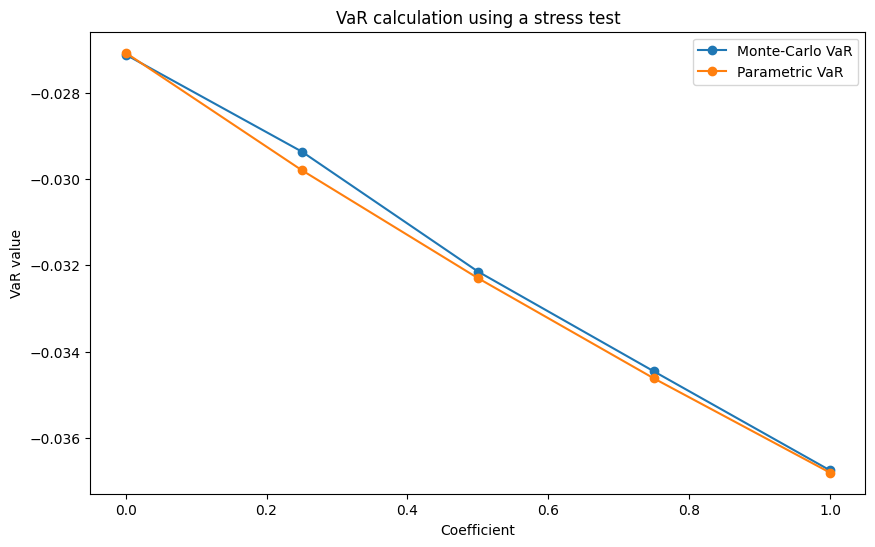

In [17]:
plt.figure (figsize= (10,6))
plt.plot (stress_test_table.index, stress_test_table ['VaR MC'], marker='o', label = 'Monte-Carlo VaR')
plt.plot (stress_test_table.index, stress_test_table ['VaR param'], marker = 'o', label = 'Parametric VaR')
plt.title ('VaR calculation using a stress test')
plt.xlabel ('Coefficient')
plt.ylabel ('VaR value')
plt.legend ()
plt.show ()

In [18]:
np.allclose (np.sqrt(weights.T @ daily_returns.cov() @ weights), portfolio_std_dev) 

True

In [19]:
corr_stress = (1 - 1) * corr + 1 * np.ones_like (daily_returns.corr())
cov_stress = np.diag (std) @ corr_stress @ np.diag (std)
np.sqrt(np.dot (weights.T, np.dot ((cov_stress), weights)))


np.float64(0.023052119940029397)

# Backtesting

## Test de Kupiec

In [20]:
n = len (pnl)
x = pnl [pnl < param_var_95].count ()  #nb of days where daily return is less than than the parametric_VaR
alpha = 1 - p_95 #theorical/expected probability of failure
p = x/n  # real probability of failure

ll0 = x * np.log (alpha) + (n-x) * np.log (1 - alpha)
ll1 = x * np.log (p) + (n-x) * np.log (1-p)

LR = -2 * (ll0 - ll1) #Likelihood ratio

print (f'===============  Niveau de confiance : {p_95*100}%  ===============')
print (f'Probabilité d\'échecs observée : {p:.4f}\n'
       f'Ratio de vraisemblance : {LR:.4f}')

if LR <= chi2.ppf (0.95, df = 1) :  #corresponds to the chi-squared distribution for a 5% significance level
    print ('Modèle de VaR non rejeté')
else : 
    print ('Ecart trop grand, modèle de VaR rejeté')

===============  Niveau de confiance : 95.0%  ===============
Probabilité d'échecs observée : 0.0471
Ratio de vraisemblance : 0.2754
Modèle de VaR non rejeté


In [21]:
n = len (pnl)
x = pnl [pnl < param_var_99].count ()  #nb of days where daily return is less than than the parametric_VaR
alpha = 1 - p_99 #probabilité d'échecs théorique
p = x/n  #probabilité d'échecs observée

ll0 = x * np.log (alpha) + (n-x) * np.log (1 - alpha)
ll1 = x * np.log (p) + (n-x) * np.log (1-p)

LR = -2 * (ll0 - ll1) #Likelihood ratio
print (f'===============  Niveau de confiance : {p_99*100}%  ===============')
print (f'Probabilité d\'échecs observée : {p:.4f}\n'
       f'Ratio de vraisemblance : {LR:.4f}')


if LR <= chi2.ppf (0.95, df = 1) :  #corresponds to the chi-squared distribution for a 5% significance level
    print ('Modèle de VaR non rejeté')
else : 
    print ('Ecart trop grand, modèle de VaR rejeté')

===============  Niveau de confiance : 99.0%  ===============
Probabilité d'échecs observée : 0.0172
Ratio de vraisemblance : 6.5659
Ecart trop grand, modèle de VaR rejeté


## Rolling backtesting

In [22]:
#Dans cette étape, on va calculer la VaR quotidienne en ajustant nos données à chaque fois sur les 250 derniers jours (soit 1 an)

w = 250 #longueur de la fenêtre, le nombre de jours ouvrés (trading days) sur 1 an
n = len (daily_returns)
window = pd.DataFrame(index=daily_returns.index, columns=['Daily Returns', 'VaR'], dtype=float)
window ['Daily Returns'] = pnl
for i in range (w, n) :
    window_ret = daily_returns.iloc [i-w:i]
    window_port_ret = window_ret.mean (axis= 0) * weights
    window_port_std = np.sqrt (weights.T @ window_ret.cov() @ weights)
    window_var = window_port_ret.sum() - (norm.ppf(p_95) * window_port_std)
    window.iloc [i, 1] = window_var
print (window)

            Daily Returns       VaR
Date                               
2017-01-04       0.020484       NaN
2017-01-05      -0.011668       NaN
2017-01-06      -0.003167       NaN
2017-01-09       0.012897       NaN
2017-01-10      -0.001528       NaN
...                   ...       ...
2022-12-23       0.002700 -0.039898
2022-12-27      -0.026711 -0.039830
2022-12-28      -0.009385 -0.039993
2022-12-29       0.023636 -0.040027
2022-12-30      -0.000602 -0.039998

[1508 rows x 2 columns]


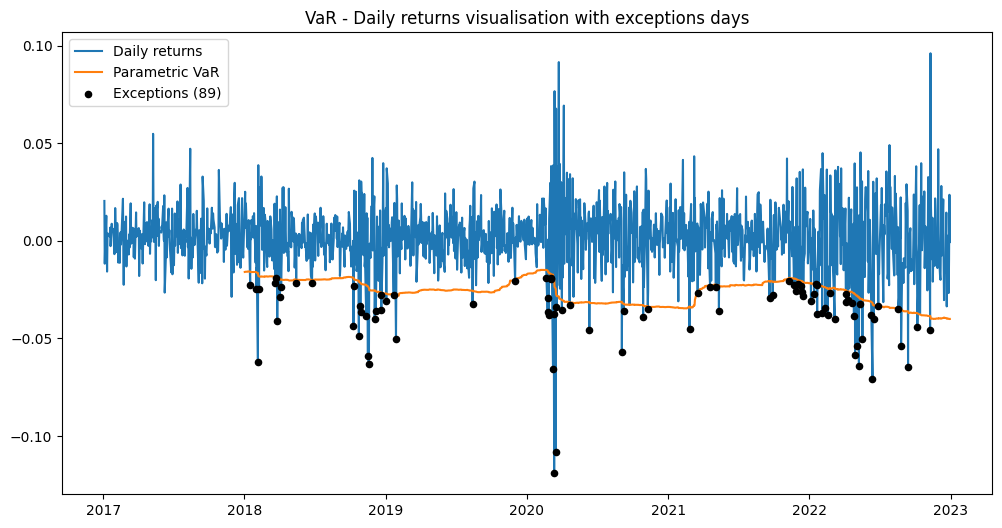

In [23]:
exceptions = window[window['Daily Returns'] < window['VaR']]

plt.figure (figsize= (12,6))
plt.plot (window.index, window ['Daily Returns'], label = 'Daily returns')
plt.plot (window.index, window ['VaR'], label = 'Parametric VaR')
plt.scatter(exceptions.index, exceptions['Daily Returns'],
            color='black', s=20, zorder=3, label=f'Exceptions ({len(exceptions)})')
plt.legend ()
plt.title ('VaR - Daily returns visualisation with exceptions days')
plt.show()

In [24]:
window_clean = window[window['VaR'].notna()]

print (f'This rolling window model shows that we have {len (exceptions)} exception days out of {len (window_clean)},' 
       f'this is {len(exceptions)*100/len(window_clean):.2f}% days.\n' 
       f'As we expected a 5% ({0.05 * len(window_clean):.4f}) days of exceptions')

if len (exceptions) > 0.05 * len (window_clean) :
    print ('The VaR rolling window model for 250-day is not the best fitted model for our risk management')
else : 
    print ('The VaR rolling window model can be accepted for our risk management')

This rolling window model shows that we have 89 exception days out of 1258,this is 7.07% days.
As we expected a 5% (62.9000) days of exceptions
The VaR rolling window model for 250-day is not the best fitted model for our risk management
